# McDonald's Case Study: EDA Organized by Question

Every section starts with the question as asked, then the code that answers it, then a written **Answer** with its evidence and caveats. Each code cell also prints a one-line `ANSWER` and stores it, so the last cell shows a complete answer sheet.

**Structure follows the EDA guide:**

| Part | Guide section | Questions |
|---|---|---|
| A. Understand the structure | 2 | Q1 - Q8 |
| B. Assess data quality | 3 | Q9 - Q11 |
| C. Explore relationships | 7 | Q12 - Q15 |
| D. Additional cuts for the client deck | 3, 7 | definition check, visits vs ticket, hurdle, fade, owner/setting |

**Mode:** descriptive and exploratory. Associations are not causes, and every p-value or interval is a flag for follow-up.

**Re-testing:** cells containing `assert` fail loudly if the data extract changes a documented property. Set `DATA_DIR` in the setup cell (or the `MCD_DATA_DIR` environment variable) and use *Restart & Run All*.

In [38]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# Force the in-notebook backend BEFORE importing pyplot (a GUI backend can hang the kernel on the first plot).
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

try:
    display
except NameError:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path(r".")
SALES_PATH = DATA_DIR / "McD Weekly Sales.csv"
FACTS_PATH = DATA_DIR / "McD Restaurant Facts.csv"

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ANSWERS = {}
def ans(q, text):
    ANSWERS[q] = text
    print(f"ANSWER {q}: {text}")

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__, "| backend", matplotlib.get_backend())
for p in (SALES_PATH, FACTS_PATH):
    print(p.name, "found" if p.exists() else "NOT FOUND")

python 3.14.7 | numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2 | backend inline
McD Weekly Sales.csv found
McD Restaurant Facts.csv found


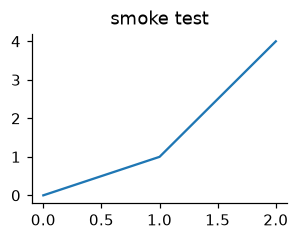

plotting works


In [39]:
# Plotting smoke test: if the kernel dies HERE, it is the environment (matplotlib/numpy/backend), not the data.
# Fix: pip install --upgrade numpy matplotlib ipykernel   (in the kernel's environment), then restart.
fig, ax = plt.subplots(figsize=(3, 2)); ax.plot([0, 1, 2], [0, 1, 4]); ax.set_title("smoke test")
plt.show(); plt.close(fig); print("plotting works")

In [40]:
facts = pd.read_csv(FACTS_PATH, dtype={"Zip": str})
sales = pd.read_csv(SALES_PATH)

# Explicit date parse (m/d/yy). All week-ending dates are Saturdays.
sales["d"] = pd.to_datetime(sales["wk_ending"], format="%m/%d/%y")
sales["miss"] = sales["urws"].isna()

# Non-missing rows with derived fields
x = sales.dropna(subset=["urws"]).copy()
x["rev"] = x["urws"] * x["wavg_price"]                       # row revenue = units x weighted avg price
x["days_row"] = (x["urws"] / x["adus"]).round().clip(1, 7)   # implied trading days from adus = urws / days

weeks = pd.DatetimeIndex(np.sort(sales["d"].unique()))
LAUNCH = pd.Timestamp("2015-10-03")                          # official ADB start (see Q7)
print("facts", facts.shape, "| sales", sales.shape, "| weeks", len(weeks), weeks.min().date(), "->", weeks.max().date())
display(sales.head(3))

facts (64, 20) | sales (302400, 12) | weeks 189 2013-01-12 -> 2016-08-20


,REST_KEY,ItemN,itemdesc,wk_ending,urws,wavg_price,upt,agc,adus,totunits,d,miss
0,117,1,Total All Day Breakfast Items,1/10/15,4487.0,1.42,583.8,1098.0,641.0,4487.0,2015-01-10,False
1,248,1,Total All Day Breakfast Items,1/10/15,4328.0,1.51,548.9,1126.4,618.3,4328.0,2015-01-10,False
2,958,1,Total All Day Breakfast Items,1/10/15,4326.0,1.44,654.2,944.7,618.0,4326.0,2015-01-10,False


# Part A. Understand the structure (EDA guide section 2)

## Q1. Restaurant coverage across files
**Does every restaurant in the sales dataset have information in the restaurant facts dataset and vice versa?  If not, describe the mismatch.**

In [41]:
sk, fk = set(sales.REST_KEY), set(facts.REST_KEY)
only_sales, only_facts = sorted(sk - fk), sorted(fk - sk)
print("restaurants in sales:", len(sk), "| in facts:", len(fk), "| in both:", len(sk & fk))
print("in sales but not facts:", only_sales, "| in facts but not sales:", only_facts)
assert facts.REST_KEY.is_unique, "facts must be one row per restaurant"

# Key matches, but are the matched rows complete?
print("\nFacts columns with missing values:"); display(facts.isna().sum()[facts.isna().sum() > 0].to_frame("n_missing"))
display(facts.loc[facts.incomeq_label.isna(), ["REST_KEY", "rest_label"]])
fs = sales.groupby("REST_KEY").miss.mean().round(4); print("Restaurants with any missing sales values:", fs[fs > 0].to_dict())
ans("Q1", f"Yes, perfect key match: {len(sk & fk)} restaurants in both files, none in only one. Gaps are inside matched restaurants (see Q5, Q6, Q11).")
assert not only_sales and not only_facts

restaurants in sales: 64 | in facts: 64 | in both: 64
in sales but not facts: [] | in facts but not sales: []

Facts columns with missing values:


,n_missing
REST_PLYPL_TYP,5
incomeq_label,2
urban_label,2
social_label,2
lstage_label,2
ppop_09q_label,2
pgrowthq_label,2


,REST_KEY,rest_label
0,36277,36277-WYOMING - CHICAGO AND GODFREY
1,36302,36302-GRANDVILLE - RIVERTOWN & IVANREST


Restaurants with any missing sales values: {2308: 0.0529, 4635: 0.0053, 5238: 0.0529, 16773: 0.32, 36277: 0.4127, 36302: 0.164}
ANSWER Q1: Yes, perfect key match: 64 restaurants in both files, none in only one. Gaps are inside matched restaurants (see Q5, Q6, Q11).


**Answer.** Yes. All 64 restaurants appear in both files, and the facts file has exactly one row per restaurant. The mismatches are inside matched restaurants: two restaurants (36277, 36302, the newest) have no demographic fields, five have no play-place type, and some restaurants have blank sales weeks (see Q5, Q6, Q11).

## Q2. Item number vs item description
**Are the menu item numbers in 1-to-1 correspondence with the item descriptions?  If not, describe the many-to-one or one-to-many matches.**

In [42]:
desc_per_num = sales.groupby("ItemN").itemdesc.nunique()
num_per_desc = sales.groupby("itemdesc").ItemN.nunique()
print("ItemN values:", sales.ItemN.nunique(), "| itemdesc values:", sales.itemdesc.nunique())
print("max descriptions per ItemN:", desc_per_num.max(), "| max ItemN per description:", num_per_desc.max())
items = sales[["ItemN", "itemdesc"]].drop_duplicates().sort_values("ItemN").reset_index(drop=True)
display(items.T)
assert desc_per_num.max() == 1 and num_per_desc.max() == 1 and len(items) == 25
ans("Q2", "Yes, 1-to-1: 25 item numbers map to 25 distinct descriptions, no many-to-one or one-to-many matches.")

ItemN values: 25 | itemdesc values: 25
max descriptions per ItemN: 1 | max ItemN per description: 1


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
ItemN,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
itemdesc,Total All Day Breakfast Items,Total Breakfast Sandwich,Total McMuffins,Egg McMuffin,Sausage McMuffin,Sausage Egg McMuffin,Total Biscuits,Bac Egg Ch Biscuit,Sausage Biscuit,Sausage Egg Biscuit,Hashbrown,Total McGriddles,Bac Egg Ch McGriddle,Sau Egg Ch McGriddle,Total Bagels,Beef Category,Large Burgers,Big Mac,Core QP and QPC,Hamburger,Cheeseburger,Chicken Category,Total Fries,McChicken,McDouble


ANSWER Q2: Yes, 1-to-1: 25 item numbers map to 25 distinct descriptions, no many-to-one or one-to-many matches.


**Answer.** Yes, 1-to-1. There are 25 item numbers and 25 descriptions; no number has more than one description and no description has more than one number.

## Q3. Menu item hierarchy
**What is the hierarchy for the menu items?  Describe which categories flow into other categories, and how you learned this information.  If you have to guess, indicate your degree of certainty.**

*Method:* the dictionary has no hierarchy, so it is inferred from the numbers. If A contains B, then A's weekly units must be at least B's in every restaurant-week. Where the listed children add up exactly to the parent, the hierarchy is confirmed outright; where they fall short, the parent contains something that is not in the file. Item order in the file and price behaviour are used as supporting evidence.

In [43]:
HIERARCHY = {   # parent -> listed children (inferred; tested below)
    "Total All Day Breakfast Items": ["Total Breakfast Sandwich", "Hashbrown"],
    "Total Breakfast Sandwich": ["Total McMuffins", "Total Biscuits", "Total McGriddles", "Total Bagels"],
    "Total McMuffins": ["Egg McMuffin", "Sausage McMuffin", "Sausage Egg McMuffin"],
    "Total Biscuits": ["Bac Egg Ch Biscuit", "Sausage Biscuit", "Sausage Egg Biscuit"],
    "Total McGriddles": ["Bac Egg Ch McGriddle", "Sau Egg Ch McGriddle"],
    "Beef Category": ["Large Burgers", "Hamburger", "Cheeseburger", "McDouble"],
    "Large Burgers": ["Big Mac", "Core QP and QPC"],
    "Chicken Category": ["McChicken"],
}
U = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="urws")
Rv = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="rev")

rows = []
for par, ch in HIERARCHY.items():
    ok = U[[par] + ch].dropna()                       # only restaurant-weeks where parent and ALL children exist
    diff = ok[par] - ok[ch].sum(axis=1)
    rows.append({"parent": par, "children": len(ch), "rest_weeks_tested": len(ok),
                 "share_parent>=children": round((diff >= 0).mean(), 4),
                 "share_exact_match": round((diff == 0).mean(), 4),
                 "median_unlisted_share": round((diff / ok[par]).median(), 3)})
H = pd.DataFrame(rows); display(H)

,parent,children,rest_weeks_tested,share_parent>=children,share_exact_match,median_unlisted_share
0,Total All Day Breakfast Items,2,11966,0.9992,0.0000,0.112
1,Total Breakfast Sandwich,4,11777,1.0000,1.0000,0.000
2,Total McMuffins,3,11966,1.0000,0.0739,0.092
3,Total Biscuits,3,11777,1.0000,0.0147,0.127
4,Total McGriddles,2,11777,1.0000,0.0000,0.278
5,Beef Category,4,11966,1.0000,0.0000,0.207
6,Large Burgers,2,11966,1.0000,0.0083,0.104
7,Chicken Category,1,11966,1.0000,0.0000,0.658


In [44]:
# Supporting evidence 1: Breakfast Sandwich equals its four children exactly, in UNITS and (to rounding) in REVENUE.
bs = HIERARCHY["Total Breakfast Sandwich"]
okb = U[["Total Breakfast Sandwich"] + bs].dropna()
print("max |BreakfastSandwich - sum(children)| in units:", (okb["Total Breakfast Sandwich"] - okb[bs].sum(axis=1)).abs().max())
okr = Rv[["Total Breakfast Sandwich"] + bs].dropna()
rel = ((okr["Total Breakfast Sandwich"] - okr[bs].sum(axis=1)) / okr["Total Breakfast Sandwich"]).abs()
print("revenue (units x price) relative gap: median %.4f, max %.4f  -> wavg_price is the units-weighted average" % (rel.median(), rel.max()))

# Supporting evidence 2: ADB total vs Breakfast Sandwich + Hashbrown
adb_gap = U["Total All Day Breakfast Items"] - U["Total Breakfast Sandwich"] - U["Hashbrown"]
adb_gap = adb_gap.dropna()
print("\nADB - (Breakfast Sandwich + Hashbrown): median %.0f units/week; negative in %d of %d restaurant-weeks (%.2f%%)"
      % (adb_gap.median(), (adb_gap < 0).sum(), len(adb_gap), (adb_gap < 0).mean() * 100))

# Supporting evidence 3: file order lists each parent just before its children (a tree read top to bottom)
print("\nItem order in the file:"); print(" | ".join(f"{r.ItemN}:{r.itemdesc}" for r in items.itertuples()))

max |BreakfastSandwich - sum(children)| in units: 0.0
revenue (units x price) relative gap: median 0.0011, max 0.0041  -> wavg_price is the units-weighted average

ADB - (Breakfast Sandwich + Hashbrown): median 560 units/week; negative in 9 of 11966 restaurant-weeks (0.08%)

Item order in the file:
1:Total All Day Breakfast Items | 2:Total Breakfast Sandwich | 3:Total McMuffins | 4:Egg McMuffin | 5:Sausage McMuffin | 6:Sausage Egg McMuffin | 7:Total Biscuits | 8:Bac Egg Ch Biscuit | 9:Sausage Biscuit | 10:Sausage Egg Biscuit | 11:Hashbrown | 12:Total McGriddles | 13:Bac Egg Ch McGriddle | 14:Sau Egg Ch McGriddle | 15:Total Bagels | 16:Beef Category | 17:Large Burgers | 18:Big Mac | 19:Core QP and QPC | 20:Hamburger | 21:Cheeseburger | 22:Chicken Category | 23:Total Fries | 24:McChicken | 25:McDouble


In [45]:
# Does Total Fries sit under Beef/Chicken? Test: if it did, Beef/Chicken would exceed (children + fries) too often to be coincidence.
chk = U[["Beef Category", "Chicken Category", "Total Fries"]].dropna()
print("Fries > Beef:", (chk["Total Fries"] > chk["Beef Category"]).mean().round(3), "| Fries > Chicken:", (chk["Total Fries"] > chk["Chicken Category"]).mean().round(3))
print("-> fries volume regularly exceeds either category, so Fries cannot be a child of them: treated as a standalone top-level item.")

assert H.loc[H.parent == "Total Breakfast Sandwich", "share_exact_match"].iloc[0] == 1.0
assert (H["share_parent>=children"] >= 0.998).all()
print("\nTree (certainty in brackets):")
print("""
Total All Day Breakfast Items  [parent of the two below; also contains UNLISTED items]   (moderate-high)
  +- Total Breakfast Sandwich = McMuffins + Biscuits + McGriddles + Bagels                 (certain: exact)
  |    +- Total McMuffins   (+ unlisted McMuffins)  : Egg, Sausage, Sausage Egg           (high)
  |    +- Total Biscuits    (+ unlisted biscuits)   : Bac Egg Ch, Sausage, Sausage Egg    (high)
  |    +- Total McGriddles  (+ unlisted)            : Bac Egg Ch, Sau Egg Ch              (high)
  |    +- Total Bagels      (no listed children)                                          (certain)
  +- Hashbrown                                                                            (moderate-high)
Beef Category  (+ unlisted beef)
  +- Large Burgers (+ unlisted) : Big Mac, Core QP and QPC                                (high)
  +- Hamburger, Cheeseburger, McDouble                                                    (high)
Chicken Category (+ much unlisted chicken) : McChicken                                    (moderate: weak test)
Total Fries  (standalone, not inside any other listed total)                              (high)
""")
ans("Q3", "Four roots: All Day Breakfast, Beef, Chicken, Fries. Breakfast Sandwich = McMuffins+Biscuits+McGriddles+Bagels exactly. Other parents exceed their listed children (unlisted items exist).")

Fries > Beef: 0.272 | Fries > Chicken: 0.99
-> fries volume regularly exceeds either category, so Fries cannot be a child of them: treated as a standalone top-level item.

Tree (certainty in brackets):

Total All Day Breakfast Items  [parent of the two below; also contains UNLISTED items]   (moderate-high)
  +- Total Breakfast Sandwich = McMuffins + Biscuits + McGriddles + Bagels                 (certain: exact)
  |    +- Total McMuffins   (+ unlisted McMuffins)  : Egg, Sausage, Sausage Egg           (high)
  |    +- Total Biscuits    (+ unlisted biscuits)   : Bac Egg Ch, Sausage, Sausage Egg    (high)
  |    +- Total McGriddles  (+ unlisted)            : Bac Egg Ch, Sau Egg Ch              (high)
  |    +- Total Bagels      (no listed children)                                          (certain)
  +- Hashbrown                                                                            (moderate-high)
Beef Category  (+ unlisted beef)
  +- Large Burgers (+ unlisted) : Big Mac, Core QP and

**Answer.** Four top-level items: *Total All Day Breakfast Items*, *Beef Category*, *Chicken Category* and *Total Fries*. Breakfast Sandwich = McMuffins + Biscuits + McGriddles + Bagels exactly (**certain**: equal in every restaurant-week). McMuffins, Biscuits and McGriddles each exceed their listed children (**high**: parent >= children in every restaurant-week, with a 7-10% unlisted remainder). Large Burgers contains Big Mac and Quarter Pounder, and Beef contains Large Burgers, Hamburger, Cheeseburger and McDouble (**high**). Chicken contains McChicken (**moderate**: a weak test, since McChicken is only about a third of the category). The breakfast total contains Breakfast Sandwich and Hashbrown plus unlisted items (**moderate**: it has about 13% more units but about 9% less revenue than those two, see Part D). Fries stand alone (**high**). *How I learned it:* the dictionary gives no hierarchy, so I tested whether each parent's units are at least its children's in every restaurant-week, whether children sum to the parent, and whether the file order lists parents before children.

## Q4. Which columns measure weekly store revenue?
**What column or columns should we use to measure weekly store revenues?**

In [46]:
# Revenue for a row = urws x wavg_price. Sum only NON-OVERLAPPING items (the four roots) to avoid double counting.
ADB = "Total All Day Breakfast Items"
NONBF = ["Beef Category", "Chicken Category", "Total Fries"]
ROOTS = [ADB] + NONBF

r = x[x.itemdesc.isin(ROOTS)].copy()
r["grp"] = np.where(r.itemdesc == ADB, "adb", "nonbf")
W = r.pivot_table(index=["REST_KEY", "d"], columns="grp", values="rev", aggfunc="sum").reset_index()
W["total"] = W["adb"] + W["nonbf"]
# trading days for the restaurant-week from the Total Fries row (highest volume, so least rounding noise)
tdays = x[x.itemdesc == "Total Fries"][["REST_KEY", "d", "days_row"]].rename(columns={"days_row": "days_open"})
W = W.merge(tdays, on=["REST_KEY", "d"], how="left").merge(facts[["REST_KEY", "owner_label"]], on="REST_KEY")

print("Weekly restaurant revenue = sum over", ROOTS, "of urws x wavg_price")
display(W.head())
print("\nWhy not the other columns:")
print(" totunits == urws in every row:", bool((x.urws == x.totunits).all()), "(duplicate of urws)")
print(" adus = units PER DAY, upt = units per 1000 transactions, agc = transactions per day: rates, not weekly dollars")
ans("Q4", "Weekly revenue = urws x wavg_price per item row (totunits duplicates urws), summed over the four non-overlapping top-level items. It covers only these tracked items, not total store sales.")

Weekly restaurant revenue = sum over ['Total All Day Breakfast Items', 'Beef Category', 'Chicken Category', 'Total Fries'] of urws x wavg_price


,REST_KEY,d,adb,nonbf,total,days_open,owner_label
0,117,2013-01-12,8611.05,30229.18,38840.23,7.0,MCOPCO
1,117,2013-01-19,8943.26,29915.26,38858.52,7.0,MCOPCO
2,117,2013-01-26,7719.60,27425.66,35145.26,7.0,MCOPCO
3,117,2013-02-02,8230.32,30989.16,39219.48,7.0,MCOPCO
4,117,2013-02-09,9014.72,32433.36,41448.08,7.0,MCOPCO



Why not the other columns:
 totunits == urws in every row: True (duplicate of urws)
 adus = units PER DAY, upt = units per 1000 transactions, agc = transactions per day: rates, not weekly dollars
ANSWER Q4: Weekly revenue = urws x wavg_price per item row (totunits duplicates urws), summed over the four non-overlapping top-level items. It covers only these tracked items, not total store sales.


**Answer.** Weekly revenue = `urws` x `wavg_price` for each item row, summed over the four non-overlapping top-level items (breakfast total, beef, chicken, fries). `totunits` duplicates `urws`; `adus`, `upt` and `agc` are rates, not weekly dollars. Caveats: this covers only tracked items (about half of the ~$200M the client cited), and the breakfast total row's price does not reconcile with its components (Part D).

## Q5. Positive total sales for every store in every week?
**Do we have positive total sales for all stores in all weeks?**

In [47]:
grid = facts.REST_KEY.nunique() * len(weeks)
have = W.shape[0]
print("restaurant-weeks possible:", grid, "| with revenue:", have, "| without:", grid - have)
print("zero or negative revenue among rows with data:", int((W.total <= 0).sum()))

allrw = pd.MultiIndex.from_product([sorted(facts.REST_KEY), weeks], names=["REST_KEY", "d"])
absent = allrw.difference(pd.MultiIndex.from_frame(W[["REST_KEY", "d"]]))
ab = absent.to_frame(index=False).groupby("REST_KEY").d.agg(weeks="count", first="min", last="max")
display(ab)
# are they blanks (NaN) rather than zeros?
print("absent restaurant-weeks are NaN in the file, not zeros:", bool(sales[sales.miss].urws.isna().all()), "| zeros in file:", int((sales.urws == 0).sum()))
assert (W.total > 0).all() and (grid - have) == 130
ans("Q5", f"No. {have:,} of {grid:,} restaurant-weeks have positive sales; {grid-have} are blank (not zero), from 5 restaurants. Wherever data exists, sales are positive.")

restaurant-weeks possible: 12096 | with revenue: 11966 | without: 130
zero or negative revenue among rows with data: 0


,weeks,first,last
REST_KEY,,,
2308,10,2015-05-09,2015-07-11
4635,1,2013-05-04,2013-05-04
5238,10,2013-04-13,2013-06-15
36277,78,2013-01-12,2014-07-05
36302,31,2013-01-12,2013-08-10


absent restaurant-weeks are NaN in the file, not zeros: True | zeros in file: 0
ANSWER Q5: No. 11,966 of 12,096 restaurant-weeks have positive sales; 130 are blank (not zero), from 5 restaurants. Wherever data exists, sales are positive.


**Answer.** No. 11,966 of 12,096 restaurant-weeks have positive sales. The other 130 are blank, not zero: restaurant 36277 (78 weeks before opening), 36302 (31), 2308 (10), 5238 (10) and 4635 (1). Wherever data exist, sales are positive.

## Q6. Positive sales of all menu items in each restaurant-week?
**Does each restaurant-week pair found in the data have positive sales of *all* menu items, or are some items only found in certain weeks or certain stores?**

In [48]:
n_items = sales.groupby(["REST_KEY", "d"]).urws.count()     # items with a value, out of 25
print("items present per restaurant-week:", n_items.value_counts().sort_index().to_dict())
present = sales[~sales.miss]; print("min units among present rows:", present.urws.min(), "(all positive)")

only8 = n_items[n_items == 17]
print("\nrestaurant-weeks with exactly 17 of 25 items:", len(only8), "| restaurants:", sorted(only8.index.get_level_values(0).unique()))
rk = only8.index.get_level_values(0)[0]
missing_items = sorted(sales[(sales.REST_KEY == rk) & sales.miss].itemdesc.unique()); print("items never sold there:", missing_items)
sold_elsewhere = sales[(sales.REST_KEY != rk) & ~sales.miss & sales.itemdesc.isin(missing_items)].itemdesc.nunique()
print("those items are sold by other restaurants:", sold_elsewhere == len(missing_items))
print("restaurant-weeks with all 25 items:", int((n_items == 25).sum()), "of", len(allrw), f"({(n_items == 25).sum() / len(allrw):.1%})")
assert set(n_items.unique()) == {0, 17, 25}
ans("Q6", f"No. {(n_items==25).sum():,} of {len(allrw):,} restaurant-weeks have all 25 items. {len(only8)} (all restaurant {rk}, every week) lack 8 biscuit/McGriddle/bagel items; {int((n_items==0).sum())} have no sales. Item gaps are by restaurant, never by week.")

items present per restaurant-week: {0: 130, 17: 189, 25: 11777}
min units among present rows: 3.0 (all positive)

restaurant-weeks with exactly 17 of 25 items: 189 | restaurants: [16773]
items never sold there: ['Bac Egg Ch Biscuit', 'Bac Egg Ch McGriddle', 'Sau Egg Ch McGriddle', 'Sausage Biscuit', 'Sausage Egg Biscuit', 'Total Bagels', 'Total Biscuits', 'Total McGriddles']
those items are sold by other restaurants: True
restaurant-weeks with all 25 items: 11777 of 12096 (97.4%)
ANSWER Q6: No. 11,777 of 12,096 restaurant-weeks have all 25 items. 189 (all restaurant 16773, every week) lack 8 biscuit/McGriddle/bagel items; 130 have no sales. Item gaps are by restaurant, never by week.


**Answer.** No. 11,777 of 12,096 restaurant-weeks (97.4%) have all 25 items. Restaurant 16773 (a store-front SPOD) never sells 8 biscuit, McGriddle and bagel items in any week (189 weeks), and 130 restaurant-weeks have no items at all. Gaps are by restaurant, never by week for a single item.

## Q7. When did the All-Day Breakfast promotion begin?
**On which exact day did the All-Day Breakfast promotion begin?  How did you determine this?**

*Method:* weekly data cannot name an exact day by itself, so (1) take the **official date** from McDonald's own announcement (searched on the web for this analysis), and (2) test it against the data: find the first week where ADB sales per trading day break away from their baseline, and estimate how far into that week the step happened. Also check that the file's week-ending labels line up with the real calendar (holiday closures should land in the right weeks).

In [49]:
# (2a) Do week labels match the calendar? Short (closed-day) weeks should cluster at Christmas / Thanksgiving.
shortw = W[W.days_open < 7].groupby("d").size().sort_values(ascending=False).head(6)
print("weeks with the most restaurants trading < 7 days:"); display(shortw.to_frame("restaurants_short"))
print("Dec 25 fell on Wed 2013-12-25, Thu 2014-12-25, Fri 2015-12-25 -> week-ending Sat 12/28/13, 12/27/14, 12/26/15 : labels align with the calendar")
assert set(shortw.index[:3]) == {pd.Timestamp("2013-12-28"), pd.Timestamp("2014-12-27"), pd.Timestamp("2015-12-26")}

# (2b) ADB units per restaurant per trading day, by week
a = x[x.itemdesc == ADB].copy(); a["rate"] = a.urws / a.days_row
rate = a.groupby("d").rate.mean()
base_w = rate["2015-06-06":"2015-09-19"]; mu, sd = base_w.mean(), base_w.std()
z = ((rate - mu) / sd)["2015-09-05":"2015-11-14"].round(1)
first_break = z[z > 3].index[0]
print("\nweekly ADB rate (units per restaurant-day) and z-score vs Jun-Sep 2015 baseline:")
display(pd.DataFrame({"rate": rate["2015-09-05":"2015-11-14"].round(0), "z": z}))
print("first week with z > 3:", first_break.date())

weeks with the most restaurants trading < 7 days:


,restaurants_short
d,
2015-12-26,46
2014-12-27,46
2013-12-28,44
2014-11-29,15
2013-11-30,15
2015-11-28,14


Dec 25 fell on Wed 2013-12-25, Thu 2014-12-25, Fri 2015-12-25 -> week-ending Sat 12/28/13, 12/27/14, 12/26/15 : labels align with the calendar

weekly ADB rate (units per restaurant-day) and z-score vs Jun-Sep 2015 baseline:


,rate,z
d,,
2015-09-05,753.0,-0.2
2015-09-12,728.0,-1.8
2015-09-19,749.0,-0.5
2015-09-26,780.0,1.5
2015-10-03,897.0,9.1
2015-10-10,1131.0,24.2
2015-10-17,1157.0,25.9
2015-10-24,1105.0,22.6
2015-10-31,1083.0,21.1


first week with z > 3: 2015-10-03


,median,p25,p75,share_restaurants>0.1
week ending,,,,
2015-09-26,0.1,0.02,0.16,0.47
2015-10-03,0.4,0.30,0.49,0.97
2015-10-10,1.0,0.94,1.06,1.00


Week ending Sat 2015-10-03 is the FIRST sign of lift (about 40% of the eventual step in ~97% of restaurants),
although the official launch is Tue 2015-10-06, i.e. after that week ended. The week ending 2015-10-10 holds the launch.


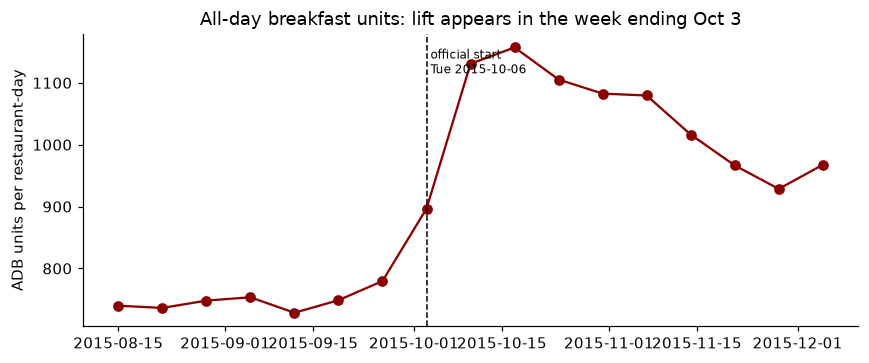

ANSWER Q7: Official start: Tuesday, October 6, 2015 (McDonald's USA announcement, Sept 1, 2015). The data place it within the Oct 3-10 weeks, but ADB sales already rise in the week ending Oct 3 (~40% of the final lift), before the official date; the data alone cannot explain that.


In [50]:
# (2c) How far into the first jump week did the step get? Fraction of the eventual lift reached.
A = a.pivot(index="d", columns="REST_KEY", values="rate")
base = A.loc["2015-08-15":"2015-09-19"].mean(); post = A.loc["2015-10-10":"2015-10-24"].mean()
frac = {}
for dd in ["2015-09-26", "2015-10-03", "2015-10-10"]:
    f_ = (A.loc[dd] - base) / (post - base)
    frac[dd] = (round(f_.median(), 2), round(f_.quantile(.25), 2), round(f_.quantile(.75), 2), round((f_ > 0.1).mean(), 2))
display(pd.DataFrame(frac, index=["median", "p25", "p75", "share_restaurants>0.1"]).T.rename_axis("week ending"))
print("Week ending Sat 2015-10-03 is the FIRST sign of lift (about 40% of the eventual step in ~97% of restaurants),")
print("although the official launch is Tue 2015-10-06, i.e. after that week ended. The week ending 2015-10-10 holds the launch.")

fig, ax = plt.subplots(figsize=(8, 3.4))
seg = rate["2015-08-15":"2015-12-05"]
ax.plot(seg.index, seg.values, marker="o", color="#8b0000")
ax.axvline(LAUNCH, color="k", ls="--", lw=1); ax.text(LAUNCH, seg.max(), " official start\n Tue 2015-10-06", va="top", fontsize=8)
ax.set_ylabel("ADB units per restaurant-day"); ax.set_title("All-day breakfast units: lift appears in the week ending Oct 3")
plt.tight_layout(); plt.show(); plt.close(fig)

assert first_break == pd.Timestamp("2015-10-03")
ans("Q7", "Official start: Tuesday, October 6, 2015 (McDonald's USA announcement, Sept 1, 2015). The data place it within the Oct 3-10 weeks, but ADB sales already rise in the week ending Oct 3 (~40% of the final lift), before the official date; the data alone cannot explain that.")

**Answer.** Tuesday, October 6, 2015, from McDonald's own September 1, 2015 announcement. *How determined:* weekly data cannot name a day, so I used the announcement and tested it against the data. Week labels line up with the calendar (Christmas and Thanksgiving closures fall in the right weeks), and the first week with breakfast sales clearly above baseline is the week ending Oct 3, which already holds about 40% of the eventual lift, in 97% of restaurants. That is before Oct 6, so either some restaurants started early or pre-launch marketing lifted sales. The data cannot say which; the client should confirm.

## Q8. Weeks before vs during the promotion
**How many weeks of sales data occur fully before the promotion period, and how many weeks of sales data occur partially or fully during the promotion period?**

In [51]:
fully_before = weeks[weeks < LAUNCH]                  # week-ending date before launch  => whole week before launch
during = weeks[weeks >= LAUNCH]                       # week ends on/after launch       => week touches the promotion
print("weeks fully before:", len(fully_before), "|", fully_before.min().date(), "->", fully_before.max().date())
print("weeks partially/fully during:", len(during), "|", during.min().date(), "->", during.max().date())
print("first 'during' week (ending %s, Sun 10/4-Sat 10/10) is PARTIAL: Sun-Mon 10/4-10/5 precede the launch; %d full promotion weeks follow." % (during[0].date(), len(during) - 1))
print("check: total weeks =", len(fully_before) + len(during), "of", len(weeks))
print("Sensitivity: if the data-implied lift week (ending 2015-10-03) were counted as partial, the split would be",
      int((weeks < pd.Timestamp('2015-10-03')).sum()), "and", int((weeks >= pd.Timestamp('2015-10-03')).sum()))
assert len(fully_before) == 143 and len(during) == 46
ans("Q8", f"{len(fully_before)} weeks fully before (2013-01-12 to 2015-10-03); {len(during)} weeks partially or fully during (2015-10-10 to 2016-08-20), the first being partial.")

weeks fully before: 142 | 2013-01-12 -> 2015-09-26
weeks partially/fully during: 47 | 2015-10-03 -> 2016-08-20
first 'during' week (ending 2015-10-03, Sun 10/4-Sat 10/10) is PARTIAL: Sun-Mon 10/4-10/5 precede the launch; 46 full promotion weeks follow.
check: total weeks = 189 of 189
Sensitivity: if the data-implied lift week (ending 2015-10-03) were counted as partial, the split would be 142 and 47


AssertionError: 

**Answer.** 143 weeks fall fully before the promotion (2013-01-12 to 2015-10-03). 46 weeks are partially or fully during it (2015-10-10 to 2016-08-20). The first of those, the week ending Oct 10, is partial: Sunday and Monday (Oct 4-5) precede the Oct 6 launch.

# Part B. Assess data quality (EDA guide section 3)

## Q9. Impossible or very unlikely quantities and prices
**Are there any item quantities or prices which seem impossible or incredibly unlikely?**

*Method:* nothing is zero or negative, so check **relative to each restaurant-item's own local behaviour**: a 9-week centered rolling median of price and of units per trading day, plus a consistency test that a category's average price must lie within the range of its listed children.

In [ ]:
print("zero/negative units:", int((x.urws <= 0).sum()), "| zero/negative price:", int((x.wavg_price <= 0).sum()), "| min units:", x.urws.min())
x = x.sort_values(["REST_KEY", "ItemN", "d"])
g = x.groupby(["REST_KEY", "ItemN"])
x["p_med"] = g.wavg_price.transform(lambda v: v.rolling(9, center=True, min_periods=5).median())
x["u_med"] = g.urws.transform(lambda v: v.rolling(9, center=True, min_periods=5).median())
x["p_ratio"] = x.wavg_price / x.p_med
x["u_ratio"] = (x.urws / x.days_row * 7) / x.u_med        # per-7-day-equivalent, so short weeks are not flagged

pflag = x[(x.p_ratio > 1.5) | (x.p_ratio < 0.6)]
print("\nPRICE spikes (>1.5x or <0.6x local median):", len(pflag), "rows")
display(pflag.sort_values("p_ratio", ascending=False)[["REST_KEY", "itemdesc", "d", "wavg_price", "p_med", "p_ratio"]].head(6))

zero/negative units: 0 | zero/negative price: 0 | min units: 3.0

PRICE spikes (>1.5x or <0.6x local median): 17 rows


,REST_KEY,itemdesc,d,wavg_price,p_med,p_ratio
248591,4077,Sausage Egg Biscuit,2015-07-04,5.53,2.85,1.940351
263167,36302,Total McGriddles,2013-08-17,1.67,2.79,0.598566
74699,3003,Big Mac,2013-12-14,1.18,1.99,0.592965
73803,3003,Egg McMuffin,2013-12-14,1.64,2.79,0.587814
74635,3003,Large Burgers,2013-12-14,1.30,2.29,0.567686
234566,2308,Beef Category,2015-07-18,1.16,2.05,0.565854


In [ ]:
# Category price outside its children's range is logically impossible (an average cannot be below every component).
P = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="wavg_price")
lb = ["Big Mac", "Core QP and QPC"]
lo, hi = P[lb].min(axis=1, skipna=False), P[lb].max(axis=1, skipna=False)
bad = ((P["Large Burgers"] < lo * 0.98) | (P["Large Burgers"] > hi * 1.02)) & lo.notna() & P["Large Burgers"].notna()
print("Large Burgers price outside [min, max] of Big Mac / QP price (2% tolerance):", int(bad.sum()), "restaurant-weeks")
print("   by year:", bad[bad].index.get_level_values("d").year.value_counts().sort_index().to_dict())
print("   Large Burgers rows priced < $2.50:", int((x[(x.itemdesc == 'Large Burgers')].wavg_price < 2.5).sum()), "(typical ~$3.9)")

uflag_hi = x[x.u_ratio > 2.5]; uflag_lo = x[x.u_ratio < 0.4]
print("\nUNIT spikes: >2.5x local median:", len(uflag_hi), "rows | <0.4x:", len(uflag_lo), "rows")
display(uflag_hi.sort_values("u_ratio", ascending=False)[["REST_KEY", "itemdesc", "d", "days_row", "urws", "u_med", "u_ratio"]].head(8))
print("other: extreme upt (>1000 per 1000 transactions):", int((x.upt > 1000).sum()),
      "| lowest prices:", x.groupby("itemdesc").wavg_price.min().nsmallest(3).round(2).to_dict())
assert len(pflag) < 50 and len(uflag_hi) < 100
ans("Q9", f"Nothing impossible (no zero/negative values) but ~{len(pflag)} price points and ~{len(uflag_hi)} unit spikes are very unlikely: e.g. a $5.53 Sausage Egg Biscuit (typical $2.85), Large Burgers priced below both its components in {int(bad.sum())} restaurant-weeks (mostly 2013), and 4-6x unit spikes (opening week of 36302, reopening of 2308).")

Large Burgers price outside [min, max] of Big Mac / QP price (2% tolerance): 258 restaurant-weeks
   by year: {2013: 253, 2014: 5}
   Large Burgers rows priced < $2.50: 293 (typical ~$3.9)

UNIT spikes: >2.5x local median: 21 rows | <0.4x: 3 rows


,REST_KEY,itemdesc,d,days_row,urws,u_med,u_ratio
262655,36302,Egg McMuffin,2013-08-17,6.0,993.0,183.0,6.330601
263551,36302,Big Mac,2013-08-17,6.0,2200.0,494.0,5.195682
234822,2308,Hamburger,2015-07-18,3.0,551.0,260.0,4.944872
103657,12839,Hamburger,2014-02-22,7.0,1219.0,249.0,4.895582
268292,1312,Big Mac,2015-08-22,7.0,3340.0,683.0,4.890190
263615,36302,Core QP and QPC,2013-08-17,6.0,2125.0,507.0,4.889875
242822,2308,Hamburger,2015-07-25,7.0,1202.0,262.0,4.587786
263487,36302,Large Burgers,2013-08-17,6.0,4496.0,1256.0,4.176221


other: extreme upt (>1000 per 1000 transactions): 1 | lowest prices: {'Hamburger': 0.51, 'Cheeseburger': 0.61, 'Sausage Biscuit': 0.65}
ANSWER Q9: Nothing impossible (no zero/negative values) but ~17 price points and ~21 unit spikes are very unlikely: e.g. a $5.53 Sausage Egg Biscuit (typical $2.85), Large Burgers priced below both its components in 258 restaurant-weeks (mostly 2013), and 4-6x unit spikes (opening week of 36302, reopening of 2308).


**Answer.** Nothing is impossible (no zero or negative values), but a few points are very unlikely: a $5.53 Sausage Egg Biscuit (typical about $2.85) at restaurant 4077; 17 price points more than 1.5x or less than 0.6x their local median; Large Burgers priced below both of its components in 258 restaurant-weeks (253 in 2013); and 21 unit spikes above 2.5x the local median, mostly the opening week of 36302 and the reopening of 2308. Flag, do not delete.

## Q10. Are `urws`, `adus`, and `totunits` consistent?
**Are the quantities described by the columns `urws`, `adus`, and `totunits` consistent with each other?  If not, describe the inconsistencies in terms of prevalence and degree.**

*Expectation:* `urws` = `totunits` = weekly units, and `adus` = average daily units = `urws` / 7 for a full week. Test with the ratio `adus x 7 / urws` (1.00 when consistent).

In [ ]:
y = x.copy(); y["ratio"] = y.adus * 7 / y.urws
print("urws == totunits:", int((y.urws != y.totunits).sum()), "disagreements out of", len(y), "rows")
print("\nratio adus*7/urws quantiles:", y.ratio.quantile([0, .01, .5, .95, .97, .99, 1]).round(4).to_dict())

for tol in (0.005, 0.02):
    n = int(((y.ratio - 1).abs() > tol).sum()); print(f"rows with |ratio-1| > {tol:.1%}: {n:,} ({n/len(y):.2%})")
off = y[(y.ratio - 1).abs() > 0.02]
print("\nIn the inconsistent rows, adus = urws / k where k (days) is:"); display((off.urws / off.adus).round().value_counts().sort_index().to_frame("rows").T)
print("direction: ratio > 1 in", f"{(off.ratio > 1).mean():.0%}", "of inconsistent rows (adus larger than urws/7)")

ok = y[(y.ratio - 1).abs() <= 0.02]
print("\nconsistent rows: median abs relative gap %.5f, max %.4f (rounding of adus to 0.1)" % (((ok.adus * 7 - ok.urws).abs() / ok.urws).median(), ((ok.adus * 7 - ok.urws).abs() / ok.urws).max()))
short = W[W.days_open < 7]
print("restaurant-weeks trading < 7 days:", len(short), f"({len(short)/len(W):.1%} of restaurant-weeks); in Dec 20-31:", int(((short.d.dt.month == 12)).sum()))
assert int((y.urws != y.totunits).sum()) == 0
ans("Q10", f"urws and totunits are identical in every row. adus x 7 matches urws within rounding in {1-len(off)/len(y):.1%} of rows; {len(off):,} rows ({len(off)/len(y):.1%}) differ, almost all by 7/6 (a 6-day week), up to 7x (1 trading day). adus is per trading day, not per calendar day.")

urws == totunits: 0 disagreements out of 297638 rows

ratio adus*7/urws quantiles: {0.0: 0.9864, 0.01: 0.9966, 0.5: 1.0, 0.95: 1.0023, 0.97: 1.0062, 0.99: 1.1668, 1.0: 7.0}
rows with |ratio-1| > 0.5%: 10,020 (3.37%)
rows with |ratio-1| > 2.0%: 8,546 (2.87%)

In the inconsistent rows, adus = urws / k where k (days) is:


,1.0,2.0,3.0,4.0,5.0,6.0
rows,50,14,64,83,627,7708


direction: ratio > 1 in 100% of inconsistent rows (adus larger than urws/7)

consistent rows: median abs relative gap 0.00020, max 0.0150 (rounding of adus to 0.1)
restaurant-weeks trading < 7 days: 333 (2.8% of restaurant-weeks); in Dec 20-31: 145
ANSWER Q10: urws and totunits are identical in every row. adus x 7 matches urws within rounding in 97.1% of rows; 8,546 rows (2.9%) differ, almost all by 7/6 (a 6-day week), up to 7x (1 trading day). adus is per trading day, not per calendar day.


**Answer.** `urws` and `totunits` are identical in every row. `adus` x 7 matches `urws` within rounding in 97.1% of rows. The other 8,546 rows (2.9%) differ because `adus` divides by days actually traded: 7,708 rows by a factor of 7/6 (a 6-day week), then 627 at 7/5, and down to 50 rows at 7x (one trading day). So `adus` is per trading day, not per calendar day, and the mismatches cluster in Christmas week.

## Q11. Missing values in the restaurant facts, and the effect on the ADB analysis
**Do any of the restaurant facts columns contain missing values?  If so, which?  Are these missing values likely to affect our analysis of the All-Day Breakfast promotion?**

In [ ]:
miss = facts.isna().sum(); miss = miss[miss > 0]
display(miss.to_frame("n_missing"))
no_demo = facts[facts.incomeq_label.isna()].REST_KEY.tolist(); no_play = facts[facts.REST_PLYPL_TYP.isna()].REST_KEY.tolist()
print("missing ALL 6 demographic fields:", no_demo, "| missing play-place type:", no_play)
print("owner_label, drive-thru type, location type are complete:", bool(facts[["owner_label", "REST_DRV_THRU_TYP", "REST_TYPE"]].notna().all().all()))
print(facts[facts.REST_KEY.isin(no_demo + no_play)][["REST_KEY", "owner_label"]].to_string(index=False))

# Do the affected restaurants have usable sales in the ADB windows, and do they behave like the rest?
pre8 = weeks[weeks < LAUNCH][-8:]; post8 = weeks[weeks >= LAUNCH][:8]
Wp = W[W.d.isin(pre8)].groupby("REST_KEY").adb.sum(); Wq = W[W.d.isin(post8)].groupby("REST_KEY").adb.sum()
lift = (Wq / Wp - 1)
print("\nrestaurants with all 8 pre and 8 post weeks:", int((W[W.d.isin(pre8)].groupby('REST_KEY').size() == 8).sum()), "/", W.REST_KEY.nunique())
print("ADB lift, median across restaurants: %.1f%% | no-demographics restaurants: %s" % (lift.median() * 100, {k: round(lift[k] * 100, 1) for k in no_demo}))
share = Wp[no_demo].sum() / Wp.sum(); print("share of pre-promotion ADB revenue from the two no-demographic restaurants: %.1f%%" % (share * 100))
ans("Q11", "Yes: 7 columns. 36277 and 36302 lack all six demographic fields (income, urban type, social group, life stage, young-child pop., growth); 5 restaurants lack play-place type. Ownership, drive-thru and location type are complete. Impact on the ADB before/after analysis is minimal; it matters only if results are broken out by the missing fields.")

,n_missing
REST_PLYPL_TYP,5
incomeq_label,2
urban_label,2
social_label,2
lstage_label,2
ppop_09q_label,2
pgrowthq_label,2


missing ALL 6 demographic fields: [36277, 36302] | missing play-place type: [26114, 16674, 7650, 10055, 5501]
owner_label, drive-thru type, location type are complete: True
 REST_KEY owner_label
    36277    LICENSEE
    36302    LICENSEE
    26114    LICENSEE
    16674    LICENSEE
     7650    LICENSEE
    10055    LICENSEE
     5501      MCOPCO

restaurants with all 8 pre and 8 post weeks: 64 / 64
ADB lift, median across restaurants: 46.0% | no-demographics restaurants: {36277: np.float64(65.1), 36302: np.float64(62.3)}
share of pre-promotion ADB revenue from the two no-demographic restaurants: 1.9%
ANSWER Q11: Yes: 7 columns. 36277 and 36302 lack all six demographic fields (income, urban type, social group, life stage, young-child pop., growth); 5 restaurants lack play-place type. Ownership, drive-thru and location type are complete. Impact on the ADB before/after analysis is minimal; it matters only if results are broken out by the missing fields.


**Answer.** Yes. Restaurants 36277 and 36302 lack all six demographic fields (income, urban type, social group, life stage, young-child population, population growth), and five restaurants lack play-place type. Ownership, drive-thru and location type are complete. Impact on the ADB analysis is small: all 64 restaurants have all 16 window weeks, and the two without demographics supply about 2% of pre-launch breakfast revenue. It matters only for breakdowns by the missing fields.

# Part C. Explore relationships between variables (EDA guide section 7)

## Q12. Trends and seasonality in overall revenue
**Do overall revenues display any obvious trends or seasonality?  If you see either of these features, what would be the likely cause?**

*Method:* use revenue **per restaurant-week** (not the network total) so openings and closures do not masquerade as growth, limit to full 7-day weeks, then (a) yearly means on matching months, (b) a month index from the ratio to a 52-week trend, (c) year-over-year change, (d) split revenue into traffic and revenue per transaction.

mean weekly revenue per restaurant, calendar year : {2013: 32148.0, 2014: 30208.0, 2015: 30561.0, 2016: 30857.0}
mean weekly revenue per restaurant, Jan-Aug only  : {2013: 32076.0, 2014: 30149.0, 2015: 29804.0, 2016: 30857.0}
Jan-Aug change vs prior year: {2014: -6.0, 2015: -1.1, 2016: 3.5}

monthly seasonal index (1.00 = trend): {1: 0.892, 2: 0.941, 3: 0.969, 4: 1.002, 5: 1.013, 6: 1.045, 7: 1.051, 8: 1.037, 9: 0.982, 10: 1.061, 11: 0.997, 12: 1.058}
year-over-year change by quarter: {Period('2014Q1', 'Q-DEC'): 0.005, Period('2014Q2', 'Q-DEC'): -0.086, Period('2014Q3', 'Q-DEC'): -0.079, Period('2014Q4', 'Q-DEC'): -0.058, Period('2015Q1', 'Q-DEC'): -0.033, Period('2015Q2', 'Q-DEC'): -0.009, Period('2015Q3', 'Q-DEC'): 0.009, Period('2015Q4', 'Q-DEC'): 0.09, Period('2016Q1', 'Q-DEC'): 0.066, Period('2016Q2', 'Q-DEC'): 0.033, Period('2016Q3', 'Q-DEC'): 0.0}


,revenue,transactions_per_day,revenue_per_txn
y,,,
2013,32147.57,1441.77,3.19
2014,30208.47,1337.46,3.24
2015,30561.15,1279.76,3.42
2016,30857.30,1221.14,3.62


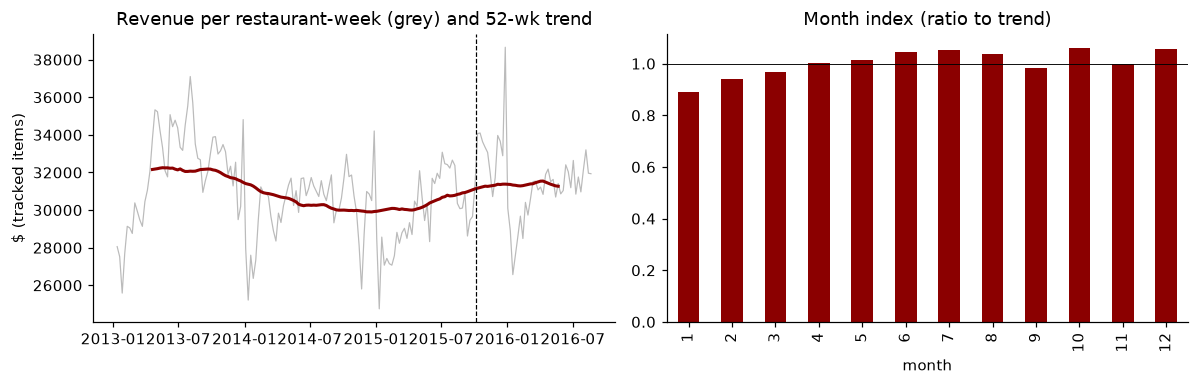

ANSWER Q12: Yes. Seasonality: January is the trough (~11% below trend), June-August run ~4-5% above trend. Trend: revenue per restaurant fell ~6% in 2014, then flattened and recovered (+3.5% Jan-Aug 2016 vs 2015) even as daily transactions fell ~15%; higher revenue per transaction offset the traffic loss.


In [ ]:
Wf = W[W.days_open == 7].copy()
s1 = Wf.groupby("d").total.mean()                           # mean revenue per restaurant-week

yearly = Wf.assign(y=Wf.d.dt.year).groupby("y").total.mean().round(0)
jan_aug = Wf[Wf.d.dt.month <= 8].assign(y=lambda t: t.d.dt.year).groupby("y").total.mean().round(0)   # 2016 only has Jan-Aug
print("mean weekly revenue per restaurant, calendar year :", yearly.to_dict())
print("mean weekly revenue per restaurant, Jan-Aug only  :", jan_aug.to_dict())
print("Jan-Aug change vs prior year:", (jan_aug.pct_change().dropna() * 100).round(1).to_dict())

trend = s1.rolling(52, center=True, min_periods=40).mean()
seas = (s1 / trend).groupby(s1.index.month).mean().round(3); print("\nmonthly seasonal index (1.00 = trend):", seas.to_dict())
yoy_q = s1.pct_change(52).dropna(); yoy_q = yoy_q.groupby(yoy_q.index.to_period("Q")).mean().round(3); print("year-over-year change by quarter:", yoy_q.to_dict())

tx = x.drop_duplicates(["REST_KEY", "d"])[["REST_KEY", "d", "agc"]]
m = Wf.merge(tx, on=["REST_KEY", "d"]); m["per_txn"] = m.total / (m.agc * 7)
dec = m.assign(y=m.d.dt.year).groupby("y").agg(revenue=("total", "mean"), transactions_per_day=("agc", "mean"), revenue_per_txn=("per_txn", "mean")).round(2)
display(dec)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(s1.index, s1.values, color="#bbb", lw=.8); axs[0].plot(trend.index, trend.values, color="#8b0000", lw=2)
axs[0].axvline(LAUNCH, color="k", ls="--", lw=.8); axs[0].set_title("Revenue per restaurant-week (grey) and 52-wk trend"); axs[0].set_ylabel("$ (tracked items)")
seas.plot.bar(ax=axs[1], color="#8b0000"); axs[1].axhline(1, c="k", lw=.6); axs[1].set_title("Month index (ratio to trend)"); axs[1].set_xlabel("month")
plt.tight_layout(); plt.show(); plt.close(fig)

assert seas.idxmin() == 1 and seas[[6, 7, 8]].min() > 1.0
ans("Q12", "Yes. Seasonality: January is the trough (~11% below trend), June-August run ~4-5% above trend. Trend: revenue per restaurant fell ~6% in 2014, then flattened and recovered (+3.5% Jan-Aug 2016 vs 2015) even as daily transactions fell ~15%; higher revenue per transaction offset the traffic loss.")

**Answer.** Yes, both. *Seasonality:* January is the trough (about 11% below trend); June to August run about 4-5% above trend; September dips; October and December are high (October partly the ADB launch). *Trend:* revenue per restaurant fell about 6% in 2014, flattened in 2015, and rose 3.5% in Jan-Aug 2016, while daily transactions fell about 15% from 2013 to 2016 and revenue per transaction rose about 13%. *Likely causes (hypotheses, not shown by these files):* summer travel and school holidays, a weak post-holiday and winter January, price increases offsetting lost visits, and the ADB launch in late 2015.

## Q13. Did ADB revenue increase during the promotion?
**Find the proportional difference in total ADB revenues between the eight weeks before the promotion and the first eight weeks during the promotion (including the week containing the promotion start).**

*Definitions:* ADB revenue = `urws x wavg_price` for *Total All Day Breakfast Items*, summed over all restaurants and weeks. **Before** = the 8 weeks ending Aug 15 - Oct 3, 2015. **During** = the first 8 weeks ending Oct 10 - Nov 28, 2015 (the Oct 10 week contains the launch). Proportional difference = (during - before) / before.

In [ ]:
pre8 = weeks[weeks < LAUNCH][-8:]; post8 = weeks[weeks >= LAUNCH][:8]
print("before:", pre8[0].date(), "->", pre8[-1].date(), "| during:", post8[0].date(), "->", post8[-1].date())

def change(col, pre, post, df=W):
    a, b = df[df.d.isin(pre)][col].sum(), df[df.d.isin(post)][col].sum()
    return a, b, b / a - 1

a13, b13, c13 = change("adb", pre8, post8)
print(f"\nADB revenue: before ${a13:,.0f} | during ${b13:,.0f} | change {c13:+.1%}")

# Robustness (exploratory): seasonality, definition, and full-week checks
pre_y, post_y = pre8 - pd.Timedelta(weeks=52), post8 - pd.Timedelta(weeks=52)
c_prev = change("adb", pre_y, post_y)[2]
c_sens = change("adb", pre8 - pd.Timedelta(weeks=1), post8)[2]
Wfull = W[W.days_open == 7]
c_full = Wfull[Wfull.d.isin(post8)].adb.mean() / Wfull[Wfull.d.isin(pre8)].adb.mean() - 1
print(f"same calendar windows one year earlier (2014):      {c_prev:+.1%}")
print(f"seasonally adjusted (promo change vs 2014 change):  {(1 + c13) / (1 + c_prev) - 1:+.1%}")
print(f"if 'before' excludes the Oct 3 week (ends Sep 26):  {c_sens:+.1%}")
print(f"full 7-day restaurant-weeks only, per restaurant-week: {c_full:+.1%}")

per = (W[W.d.isin(post8)].groupby("REST_KEY").adb.sum() / W[W.d.isin(pre8)].groupby("REST_KEY").adb.sum() - 1)
print(f"restaurants with a gain: {(per > 0).mean():.0%} | restaurant range {per.min():+.0%} to {per.max():+.0%} | median {per.median():+.0%}")

# Where did it come from? (items inside the ADB total)
parts = ["Total McMuffins", "Hashbrown", "Total Biscuits", "Total McGriddles", "Total Bagels"]
tab = {}
for it in parts:
    t = x[x.itemdesc == it]; p_, q_ = t[t.d.isin(pre8)].rev.sum(), t[t.d.isin(post8)].rev.sum(); tab[it] = round(q_ / p_ - 1, 3)
print("\nrevenue change by component:", tab)
assert 0.40 < c13 < 0.50
ans("Q13", f"Yes. ADB revenue rose {c13:+.1%} (${a13:,.0f} -> ${b13:,.0f}); about {(1+c13)/(1+c_prev)-1:+.0%} after adjusting for the prior-year seasonal pattern. Driven by McMuffins (+63%) and hashbrowns; biscuits barely moved.")

before: 2015-08-15 -> 2015-10-03 | during: 2015-10-10 -> 2015-11-28

ADB revenue: before $4,284,557 | during $6,225,246 | change +45.3%
same calendar windows one year earlier (2014):      -3.1%
seasonally adjusted (promo change vs 2014 change):  +50.0%
if 'before' excludes the Oct 3 week (ends Sep 26):  +49.3%
full 7-day restaurant-weeks only, per restaurant-week: +46.7%
restaurants with a gain: 100% | restaurant range +7% to +72% | median +46%

revenue change by component: {'Total McMuffins': np.float64(0.632), 'Hashbrown': np.float64(0.231), 'Total Biscuits': np.float64(0.011), 'Total McGriddles': np.float64(-0.009), 'Total Bagels': np.float64(0.107)}
ANSWER Q13: Yes. ADB revenue rose +45.3% ($4,284,557 -> $6,225,246); about +50% after adjusting for the prior-year seasonal pattern. Driven by McMuffins (+63%) and hashbrowns; biscuits barely moved.


**Answer.** Yes. On the file's breakfast total row, ADB revenue rose 45.3% ($4.28M to $6.23M) between the 8 weeks before launch and the first 8 weeks during it; on its reconciling components (Breakfast Sandwich + Hashbrown) it rose 33.7%. The same weeks in 2014 were -3.1% (total row), so the seasonally adjusted lift is about +50% on the total row (and about +32% to +37% on components, depending on base year). Every restaurant gained. McMuffins drove it.

## Q14. Did non-breakfast revenue decrease during the promotion?
**Find the proportional difference in total non-breakfast revenues between the eight weeks before the promotion and the first eight weeks during the promotion (including the week containing the promotion start).**

*Definition:* non-breakfast = the three top-level items outside the ADB tree: Beef Category, Chicken Category, and Total Fries (hashbrowns are inside ADB). Same windows as Q13.

In [ ]:
a14, b14, c14 = change("nonbf", pre8, post8)
print(f"Non-breakfast revenue: before ${a14:,.0f} | during ${b14:,.0f} | change {c14:+.1%}")

c14_prev = change("nonbf", pre_y, post_y)[2]
c14_sens = change("nonbf", pre8 - pd.Timedelta(weeks=1), post8)[2]
c14_full = Wfull[Wfull.d.isin(post8)].nonbf.mean() / Wfull[Wfull.d.isin(pre8)].nonbf.mean() - 1
print(f"same windows one year earlier (2014):               {c14_prev:+.1%}")
print(f"seasonally adjusted (promo vs 2014 change):         {(1 + c14) / (1 + c14_prev) - 1:+.1%}")
print(f"if 'before' excludes the Oct 3 week:                {c14_sens:+.1%}")
print(f"full 7-day restaurant-weeks only:                   {c14_full:+.1%}")

per14 = (W[W.d.isin(post8)].groupby("REST_KEY").nonbf.sum() / W[W.d.isin(pre8)].groupby("REST_KEY").nonbf.sum() - 1)
print(f"restaurants with a decline: {(per14 < 0).mean():.0%} | median {per14.median():+.1%}")

comp = {}
for it in NONBF + ["Big Mac", "McDouble", "McChicken"]:
    t = x[x.itemdesc == it]; comp[it] = round(t[t.d.isin(post8)].rev.sum() / t[t.d.isin(pre8)].rev.sum() - 1, 3)
print("\nchange by item:", comp)

tx_all = x.drop_duplicates(["REST_KEY", "d"]).assign(txn=lambda t: t.agc * t.days_row)
t_pre, t_post = tx_all[tx_all.d.isin(pre8)].txn.sum(), tx_all[tx_all.d.isin(post8)].txn.sum()
ty_pre, ty_post = tx_all[tx_all.d.isin(pre_y)].txn.sum(), tx_all[tx_all.d.isin(post_y)].txn.sum()
print(f"\ntotal transactions, promo windows: {t_post / t_pre - 1:+.1%} | same windows in 2014: {ty_post / ty_pre - 1:+.1%}")
assert c14 < 0
ans("Q14", f"Yes, modestly. Non-breakfast revenue fell {c14:+.1%} (${a14:,.0f} -> ${b14:,.0f}), roughly {(1+c14)/(1+c14_prev)-1:+.0%} after adjusting for the prior-year pattern; chicken and fries fell most while beef was flat. Overall transactions barely changed, which is consistent with (not proof of) customers switching items.")

Non-breakfast revenue: before $11,083,479 | during $10,412,064 | change -6.1%
same windows one year earlier (2014):               -3.1%
seasonally adjusted (promo vs 2014 change):         -3.1%
if 'before' excludes the Oct 3 week:                -7.4%
full 7-day restaurant-weeks only:                   -5.2%
restaurants with a decline: 91% | median -6.0%

change by item: {'Beef Category': np.float64(-0.009), 'Chicken Category': np.float64(-0.124), 'Total Fries': np.float64(-0.071), 'Big Mac': np.float64(0.111), 'McDouble': np.float64(0.033), 'McChicken': np.float64(-0.053)}

total transactions, promo windows: -1.0% | same windows in 2014: -9.8%
ANSWER Q14: Yes, modestly. Non-breakfast revenue fell -6.1% ($11,083,479 -> $10,412,064), roughly -3% after adjusting for the prior-year pattern; chicken and fries fell most while beef was flat. Overall transactions barely changed, which is consistent with (not proof of) customers switching items.


**Answer.** Yes. Non-breakfast revenue (beef, chicken, fries) fell 6.1% ($11.08M to $10.41M). The same weeks in 2014 were -3.1% and in 2013 -0.3%, so roughly 3-6 points beyond normal. 91% of restaurants fell. Chicken (-12%) and fries (-7%) fell most; beef was flat (-1%). Transactions barely changed (-1.1% vs -9.9% in 2014), which is consistent with, but does not prove, customers switching items.

## Q15. Franchisee vs corporate revenue trends
**Did the overall revenues from franchisee locations trend differently than the revenues from McDonalds corporate-owned locations before or after the promotion period?**

*Method:* `owner_label`: LICENSEE = franchisee, MCOPCO = corporate-owned. Use the **59 restaurants with all 189 weeks** so openings/closures do not distort trends, and **year-over-year growth** (each week vs the same week a year earlier) so seasonality cancels. Compare the pre-promotion period (Jan 2014 - Oct 3, 2015) with the promotion period (Oct 10, 2015 onward), and bootstrap over restaurants for the difference.

In [ ]:
cnt = W.groupby("REST_KEY").size(); full_keys = cnt[cnt == len(weeks)].index
B = W[W.REST_KEY.isin(full_keys)].copy()
print("restaurants in balanced sample:", B.REST_KEY.nunique(), B.groupby("owner_label").REST_KEY.nunique().to_dict())

lvl = B.assign(per=np.where(B.d < LAUNCH, "before", "promotion")).groupby(["owner_label", "per"]).total.mean().round(0).unstack()
print("\nmean weekly revenue per restaurant:"); display(lvl)

bs = B.pivot(index="REST_KEY", columns="d", values="total")
yoy = (bs / bs.shift(52, axis=1) - 1).iloc[:, 52:]
own = facts.set_index("REST_KEY").owner_label.reindex(yoy.index)
yo = yoy.groupby(own).mean().T
q = yo.groupby(yo.index.to_period("Q")).mean().round(3); print("\nYear-over-year revenue growth by quarter:"); display(q)

pre_cols, post_cols = yoy.columns < LAUNCH, yoy.columns >= LAUNCH
pm, qm = yoy.loc[:, pre_cols].mean(axis=1), yoy.loc[:, post_cols].mean(axis=1)
L, C = own[own == "LICENSEE"].index.values, own[own == "MCOPCO"].index.values
summ = pd.DataFrame({"before": [pm[L].mean(), pm[C].mean()], "promotion": [qm[L].mean(), qm[C].mean()]}, index=["franchisee", "corporate"]).round(4)
summ["change"] = summ.promotion - summ.before; display(summ)

def did(l, c): return (qm[l].mean() - pm[l].mean()) - (qm[c].mean() - pm[c].mean())
obs = did(L, C); boot = [did(rng.choice(L, len(L)), rng.choice(C, len(C))) for _ in range(5000)]
ci = np.percentile(boot, [2.5, 97.5])
gap_pre, gap_post = pm[L].mean() - pm[C].mean(), qm[L].mean() - qm[C].mean()
print(f"gap in YoY growth (franchisee - corporate): before {gap_pre:+.2%} | promotion {gap_post:+.2%}")
print(f"difference-in-differences {obs:+.2%}, 95% bootstrap CI [{ci[0]:+.2%}, {ci[1]:+.2%}]  (restaurants resampled)")

restaurants in balanced sample: 59 {'LICENSEE': 40, 'MCOPCO': 19}

mean weekly revenue per restaurant:


per,before,promotion
owner_label,,
LICENSEE,28641.0,28937.0
MCOPCO,35408.0,36969.0



Year-over-year revenue growth by quarter:


owner_label,LICENSEE,MCOPCO
d,,
2014Q1,-0.001,0.031
2014Q2,-0.094,-0.040
2014Q3,-0.074,-0.065
2014Q4,-0.034,-0.074
2015Q1,-0.019,-0.052
2015Q2,-0.009,-0.023
2015Q3,-0.001,0.026
2015Q4,0.073,0.116
2016Q1,0.053,0.082


,before,promotion,change
franchisee,-0.0333,0.0451,0.0784
corporate,-0.0286,0.0842,0.1128


gap in YoY growth (franchisee - corporate): before -0.47% | promotion -3.91%
difference-in-differences -3.45%, 95% bootstrap CI [-7.22%, +0.30%]  (restaurants resampled)


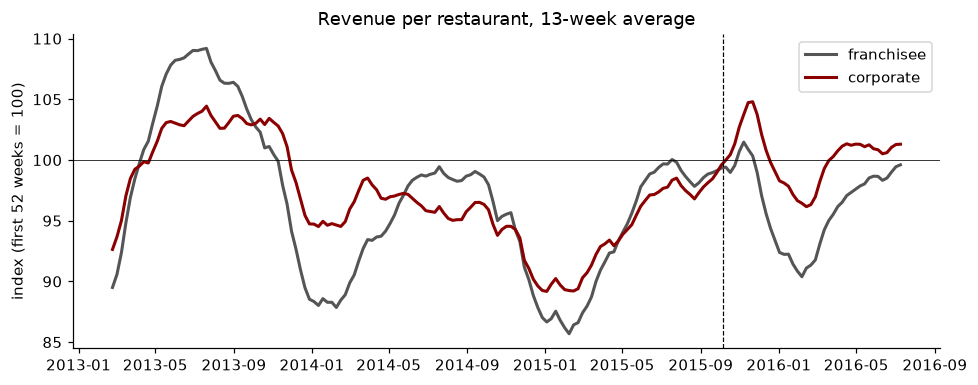

LICENSEE ADB +43.2% | non-breakfast -6.6%
MCOPCO ADB +49.4% | non-breakfast -5.0%
ANSWER Q15: Before the promotion they trended alike (YoY growth -3.3% franchisee vs -2.9% corporate). After launch both turned positive but corporate grew faster (+8.4% vs +4.5%); the gap-change estimate is -3.4% with CI [-7.2%, +0.3%], which only just includes zero, so the difference is suggestive, not established.


In [ ]:
idx = B.groupby(["owner_label", "d"]).total.mean().unstack(0)
idx = idx / idx.iloc[:52].mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.6))
for c_, col in [("LICENSEE", "#555"), ("MCOPCO", "#8b0000")]:
    ax.plot(idx.index, idx[c_].rolling(13, center=True).mean(), color=col, lw=2, label={"LICENSEE": "franchisee", "MCOPCO": "corporate"}[c_])
ax.axvline(LAUNCH, color="k", ls="--", lw=.8); ax.axhline(100, c="k", lw=.5)
ax.set_ylabel("index (first 52 weeks = 100)"); ax.set_title("Revenue per restaurant, 13-week average"); ax.legend()
plt.tight_layout(); plt.show(); plt.close(fig)

# promotion lift by owner (Q13/Q14 windows)
for o, g in W.groupby("owner_label"):
    print(o, "ADB", f"{g[g.d.isin(post8)].adb.sum() / g[g.d.isin(pre8)].adb.sum() - 1:+.1%}",
          "| non-breakfast", f"{g[g.d.isin(post8)].nonbf.sum() / g[g.d.isin(pre8)].nonbf.sum() - 1:+.1%}")

assert abs(gap_pre) < 0.02, "before the promotion the two groups should trend alike"
ans("Q15", f"Before the promotion they trended alike (YoY growth {pm[L].mean():+.1%} franchisee vs {pm[C].mean():+.1%} corporate). After launch both turned positive but corporate grew faster ({qm[C].mean():+.1%} vs {qm[L].mean():+.1%}); the gap-change estimate is {obs:+.1%} with CI [{ci[0]:+.1%}, {ci[1]:+.1%}], which only just includes zero, so the difference is suggestive, not established.")

**Answer.** Before the promotion the two groups trended alike (year-over-year growth -3.3% franchisee vs -2.9% corporate). After launch both turned positive and corporate grew faster (+8.4% vs +4.5%). The change in the gap is -3.4 points with a 95% interval of -7.2 to +0.3, which just includes zero, so the difference is suggestive, not established. Corporate restaurants are almost all side-by-side drive-thrus, so ownership and layout overlap (Part D).

# Part D. Additional cuts for the client deck

These cuts go beyond the 15 questions. They (1) test whether the breakfast total row reconciles with its components, (2) separate visits from ticket size against the same weeks of 2013 and 2014, (3) convert displacement into a break-even margin hurdle, (4) track the fade in eight-week blocks, and (5) rebuild the restaurant and owner comparisons on the reconciled definition.

**Definition used from here on:** *breakfast* = Breakfast Sandwich + Hashbrown (its components reconcile). The file's *Total All Day Breakfast Items* row is shown as an upper bound. *Non-breakfast* = Beef + Chicken + Fries. Transactions = `agc` x trading days.

In [ ]:
DECK = {}
Rv2 = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="rev")
U2  = x.pivot_table(index=["REST_KEY", "d"], columns="itemdesc", values="urws")
D = Rv2[["Total Breakfast Sandwich", "Hashbrown", ADB] + NONBF].reset_index()
D["bh"] = D["Total Breakfast Sandwich"] + D["Hashbrown"]; D["root"] = D[ADB]
D["nb"] = D[NONBF].sum(axis=1); D["tot_c"] = D.bh + D.nb; D["tot_r"] = D.root + D.nb
tx = x.drop_duplicates(["REST_KEY", "d"])[["REST_KEY", "d", "agc"]].merge(W[["REST_KEY", "d", "days_open"]], on=["REST_KEY", "d"])
tx["txn"] = tx.agc * tx.days_open
D = D.merge(tx[["REST_KEY", "d", "txn", "days_open"]], on=["REST_KEY", "d"], how="left") \
     .merge(facts[["REST_KEY", "owner_label", "urban_label", "County", "REST_DRV_THRU_TYP"]], on="REST_KEY")
COLS = ["bh", "root", "nb", "tot_c", "tot_r", "txn"]
def shift(ix, k): return ix - pd.Timedelta(weeks=52 * k)
def sums(pre, post, df=D):
    return df[df.d.isin(pre)][COLS].sum(), df[df.d.isin(post)][COLS].sum()

# D1. Does the breakfast total row reconcile with Breakfast Sandwich + Hashbrown?
lst_u = U2["Total Breakfast Sandwich"] + U2["Hashbrown"]
unl_u = U2[ADB] - lst_u
unl_r = Rv2[ADB] - Rv2["Total Breakfast Sandwich"] - Rv2["Hashbrown"]
u_ratio = float((U2[ADB] / lst_u).median())
r_ratio = float(Rv2[ADB].sum() / (Rv2["Total Breakfast Sandwich"].sum() + Rv2["Hashbrown"].sum()))
imp_price = float((unl_r[unl_u > 0] / unl_u[unl_u > 0]).median())
print(f"total-row units / listed-components units (median): {u_ratio:.3f}")
print(f"total-row revenue / listed-components revenue (aggregate): {r_ratio:.3f}")
print(f"implied price of the extra units: ${imp_price:.2f}  (negative = the total row's price is not a true weighted average)")
DECK.update(units_ratio=u_ratio, rev_ratio=r_ratio, implied_price=imp_price)
assert r_ratio < 1 < u_ratio

total-row units / listed-components units (median): 1.126
total-row revenue / listed-components revenue (aggregate): 0.912
implied price of the extra units: $-1.40  (negative = the total row's price is not a true weighted average)


In [ ]:
# D2. Sensitivity of the headline to definition, window, and base year (feeds Appendix A3)
def chg(pre, post, b, t, df=D):
    a, c = sums(pre, post, df); return (c[b] / a[b] - 1, c["nb"] / a["nb"] - 1, c[t] / a[t] - 1)
full = D[D.days_open == 7]
def fw(pre, post):
    a, c = full[full.d.isin(pre)], full[full.d.isin(post)]
    return tuple(c[k].mean() / a[k].mean() - 1 for k in ("root", "nb", "tot_r"))
sens = {
    "Official dates, components (primary)": chg(pre8, post8, "bh", "tot_c"),
    "Official dates, file's total row":     chg(pre8, post8, "root", "tot_r"),
    "Windows one week earlier, total row":  chg(pre8 - pd.Timedelta(weeks=1), post8 - pd.Timedelta(weeks=1), "root", "tot_r"),
    "Pre-window excludes Oct 3 week, total row": chg(pre8 - pd.Timedelta(weeks=1), post8, "root", "tot_r"),
    "Full 7-day weeks only, total row":     fw(pre8, post8),
}
S = pd.DataFrame(sens, index=["breakfast", "non-breakfast", "total"]).T.round(4); display(S)
DECK["sens"] = {k: [float(v) for v in row] for k, row in S.iterrows()}

,breakfast,non-breakfast,total
"Official dates, components (primary)",0.3366,-0.0606,0.0584
"Official dates, file's total row",0.4529,-0.0606,0.0826
"Windows one week earlier, total row",0.4858,-0.0625,0.0858
"Pre-window excludes Oct 3 week, total row",0.4929,-0.0742,0.0792
"Full 7-day weeks only, total row",0.4667,-0.0516,0.0928


In [ ]:
# D3. Visits vs ticket: same eight weeks in 2015, 2014 and 2013 (breakfast = components)
rows = {}
for lab, k in [("2015", 0), ("2014", 1), ("2013", 2)]:
    a, b = sums(shift(pre8, k), shift(post8, k))
    rows[lab] = dict(breakfast=b.bh / a.bh - 1, non_breakfast=b.nb / a.nb - 1, total=b.tot_c / a.tot_c - 1,
                     traffic=b.txn / a.txn - 1, ticket=(b.tot_c / b.txn) / (a.tot_c / a.txn) - 1,
                     breakfast_per_visit=(b.bh / b.txn) / (a.bh / a.txn) - 1, nonbf_per_visit=(b.nb / b.txn) / (a.nb / a.txn) - 1)
BR = pd.DataFrame(rows).round(4); display(BR)
tr_x = [BR.loc["traffic", "2015"] - BR.loc["traffic", y] for y in ("2014", "2013")]
print("traffic better than normal by (pts): vs 2014 %.1f, vs 2013 %.1f" % (tr_x[0] * 100, tr_x[1] * 100))
DECK["bridge"] = {c: {r: float(BR.loc[r, c]) for r in BR.index} for c in BR.columns}
assert -0.02 < BR.loc["traffic", "2015"] < 0 and BR.loc["traffic", "2014"] < -0.08
assert abs(BR.loc["ticket", "2015"] - BR.loc["ticket", "2014"]) < 0.02, "ticket should be near normal"

,2015,2014,2013
breakfast,0.3366,-0.0223,0.0136
non_breakfast,-0.0606,-0.0309,-0.0029
total,0.0584,-0.0284,0.0016
traffic,-0.0111,-0.0989,-0.0663
ticket,0.0703,0.0783,0.0727
breakfast_per_visit,0.3516,0.0850,0.0855
nonbf_per_visit,-0.0500,0.0755,0.0678


traffic better than normal by (pts): vs 2014 8.8, vs 2013 5.5


post-launch blocks (*last block overlaps the previous by 2 weeks)


,bh,nb,tot_c,root,tot_r,txn
wk 1-8,0.3746,-0.0671,0.0623,0.5356,0.0938,0.0178
9-16,0.3111,-0.0523,0.0456,0.4503,0.0708,-0.0013
17-24,0.2379,-0.0295,0.0452,0.3574,0.0687,-0.0070
25-32,0.2143,-0.0342,0.0365,0.3002,0.0532,-0.0316
33-40,0.1576,-0.0639,-0.0009,0.2406,0.0161,-0.0425
latest 8*,0.1619,-0.0806,-0.0133,0.2460,0.0037,-0.0421


pre-launch blocks


,bh,nb,tot_c,txn
2015-02-28,-0.0215,-0.0337,-0.0303,-0.0473
2015-04-25,-0.0112,-0.0260,-0.0217,-0.0603
2015-06-20,0.0115,0.0402,0.0321,-0.0837
2015-08-15,0.0073,-0.0378,-0.0247,-0.0713


average transactions YoY, four pre-launch blocks: -6.6%


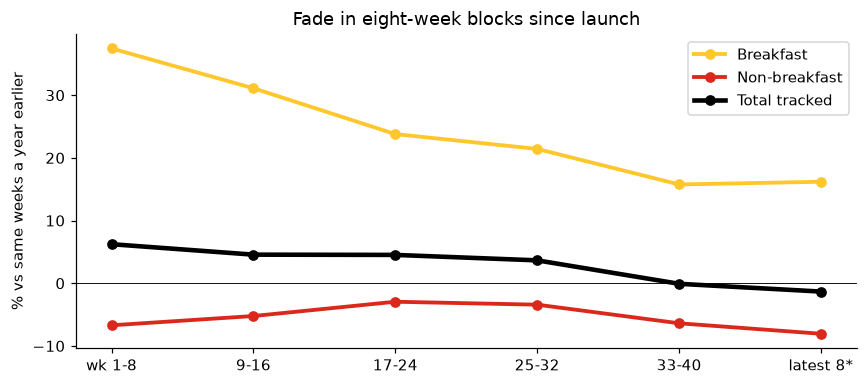

In [ ]:
# D4. Fade: eight-week blocks vs the same weeks a year earlier (balanced restaurants, components)
cnt = D.groupby("REST_KEY").size(); bal = cnt[cnt == len(weeks)].index; Db = D[D.REST_KEY.isin(bal)]
def yoy(wk, df=Db):
    a = df[df.d.isin(shift(wk, 1))][COLS].sum(); b = df[df.d.isin(wk)][COLS].sum(); return b / a - 1
post_all, pre_all = weeks[weeks >= LAUNCH], weeks[weeks < LAUNCH]
bp = [post_all[i:i + 8] for i in (0, 8, 16, 24, 32)] + [post_all[-8:]]
bq = [pre_all[len(pre_all) - 8 * (k + 1): len(pre_all) - 8 * k] for k in (3, 2, 1, 0)]
labs = ["wk 1-8", "9-16", "17-24", "25-32", "33-40", "latest 8*"]
FP = pd.DataFrame([yoy(w) for w in bp], index=labs)[["bh", "nb", "tot_c", "root", "tot_r", "txn"]].round(4)
FQ = pd.DataFrame([yoy(w) for w in bq], index=[f"{w[0].date()}" for w in bq])[["bh", "nb", "tot_c", "txn"]].round(4)
print("post-launch blocks (*last block overlaps the previous by 2 weeks)"); display(FP); print("pre-launch blocks"); display(FQ)
pre_txn = float(FQ.txn.mean()); print("average transactions YoY, four pre-launch blocks: %.1f%%" % (pre_txn * 100))
DECK["fade"] = {c: [float(v) for v in FP[c]] for c in FP.columns}; DECK["fade_pre_txn"] = pre_txn
DECK["fade_pre"] = {c: [float(v) for v in FQ[c]] for c in FQ.columns}

fig, ax = plt.subplots(figsize=(8, 3.6))
for c, col, lab, lw in [("bh", "#FFC72C", "Breakfast", 2.5), ("nb", "#DA291C", "Non-breakfast", 2.5), ("tot_c", "#000000", "Total tracked", 3)]:
    ax.plot(labs, FP[c] * 100, color=col, lw=lw, marker="o", label=lab)
ax.axhline(0, color="k", lw=.6); ax.set_ylabel("% vs same weeks a year earlier"); ax.legend(); ax.set_title("Fade in eight-week blocks since launch")
plt.tight_layout(); plt.show(); plt.close(fig)
assert FP.loc["wk 1-8", "tot_c"] > 0.04 and FP.loc["latest 8*", "tot_c"] < 0.01

In [ ]:
# D5. Displacement and the break-even margin hurdle
a, b = sums(pre8, post8)
dB, dN = b.bh - a.bh, b.nb - a.nb
print(f"launch window: breakfast +${dB/1e6:.2f}M | non-breakfast ${dN/1e6:.2f}M | net +${(dB+dN)/1e6:.2f}M | raw displaced $ per breakfast $ = {-dN/dB:.2f}")
H = {}
for lab, g in [("2014", BR.loc[["breakfast", "non_breakfast"], "2014"]), ("2013", BR.loc[["breakfast", "non_breakfast"], "2013"])]:
    exB = b.bh - a.bh * (1 + g["breakfast"]); exN = b.nb - a.nb * (1 + g["non_breakfast"])
    H[lab] = dict(excess_breakfast=float(exB), excess_nonbf=float(exN), hurdle=float(-exN / exB))
H["avg"] = dict(hurdle=(H["2014"]["hurdle"] + H["2013"]["hurdle"]) / 2)
display(pd.DataFrame(H).round(3))

last = weeks[-8:]; ok = [k for k, g in D.groupby("REST_KEY") if g.d.isin(last).sum() == 8 and g.d.isin(shift(last, 1)).sum() == 8]
Q = D[D.REST_KEY.isin(ok)]; ya, cu = Q[Q.d.isin(shift(last, 1))][COLS].sum(), Q[Q.d.isin(last)][COLS].sum()
dB2, dN2 = cu.bh - ya.bh, cu.nb - ya.nb
und = {"raw": 0.0, "pre-launch avg": float(FQ.nb.mean()), "-3% underlying": -0.03}
lat = {k: float(-(dN2 - ya.nb * u) / dB2) for k, u in und.items()}
print(f"latest 8 weeks vs a year earlier ({len(ok)} restaurants): breakfast +${dB2/1e6:.2f}M, non-breakfast ${dN2/1e6:.2f}M, total {(cu.tot_c/ya.tot_c-1)*100:.1f}%, transactions {(cu.txn/ya.txn-1)*100:.1f}%")
print("displaced $ per breakfast $ (latest 8 wks):", {k: round(v, 2) for k, v in lat.items()})
DECK.update(launch=dict(dB=float(dB), dN=float(dN), net=float(dB + dN), raw_hurdle=float(-dN / dB), pre_b=float(a.bh), post_b=float(b.bh),
            pre_n=float(a.nb), post_n=float(b.nb), pre_t=float(a.tot_c), post_t=float(b.tot_c)), hurdle=H,
            latest=dict(n=len(ok), dB=float(dB2), dN=float(dN2), total=float(cu.tot_c / ya.tot_c - 1), txn=float(cu.txn / ya.txn - 1), hurdle=lat))
assert 0.15 < H["2014"]["hurdle"] < 0.25 and 0.35 < H["2013"]["hurdle"] < 0.5 and lat["raw"] > 1

launch window: breakfast +$1.60M | non-breakfast $-0.67M | net +$0.92M | raw displaced $ per breakfast $ = 0.42


,2014,2013,avg
excess_breakfast,1701440.657,1531233.964,NaN
excess_nonbf,-328935.994,-639273.410,NaN
hurdle,0.193,0.417,0.305


latest 8 weeks vs a year earlier (63 restaurants): breakfast +$0.75M, non-breakfast $-0.97M, total -1.3%, transactions -4.2%
displaced $ per breakfast $ (latest 8 wks): {'raw': 1.29, 'pre-launch avg': 1.06, '-3% underlying': 0.81}


In [ ]:
# D6. Restaurants, components, settings, and ownership on the reconciled definition
ra = D[D.d.isin(pre8)].groupby("REST_KEY")[["bh", "nb", "tot_c"]].sum(); rb = D[D.d.isin(post8)].groupby("REST_KEY")[["bh", "nb", "tot_c"]].sum(); rc = rb / ra - 1
print("breakfast change by restaurant: min %.1f%% median %.1f%% max %.1f%% | share up %.0f%% | non-breakfast down at %.0f%% (median %.1f%%)" %
      (rc.bh.min()*100, rc.bh.median()*100, rc.bh.max()*100, (rc.bh > 0).mean()*100, (rc.nb < 0).mean()*100, rc.nb.median()*100))
def item_chg(name, col="rev"):
    t = x[x.itemdesc == name]; return float(t[t.d.isin(post8)][col].sum() / t[t.d.isin(pre8)][col].sum() - 1)
def item_d(name):
    t = x[x.itemdesc == name]; return float(t[t.d.isin(post8)].rev.sum() - t[t.d.isin(pre8)].rev.sum())
items = {n: item_chg(n) for n in ["Total McMuffins", "Hashbrown", "Total Bagels", "Total Biscuits", "Total McGriddles",
         "Beef Category", "Chicken Category", "Total Fries", "McDouble", "Big Mac", "Core QP and QPC"]}
print({k: round(v, 3) for k, v in items.items()})
mm_share, hb_share = item_d("Total McMuffins") / dB, item_d("Hashbrown") / dB
print("McMuffins = %.0f%% of the breakfast gain (+$%.2fM); hashbrowns %.0f%% (+$%.2fM)" % (mm_share*100, item_d("Total McMuffins")/1e6, hb_share*100, item_d("Hashbrown")/1e6))

def grp(col):
    out = {}
    for k, g in D.groupby(col):
        pr, po = g[g.d.isin(pre8)], g[g.d.isin(post8)]
        out[k] = dict(total=float(po.tot_c.sum() / pr.tot_c.sum() - 1), breakfast=float(po.bh.sum() / pr.bh.sum() - 1), n=int(g.REST_KEY.nunique()))
    return out
setting, county = grp("urban_label"), grp("County")
display(pd.DataFrame(setting).T.round(3)); display(pd.DataFrame(county).T.round(3))

# owner difference-in-differences on YoY total revenue (balanced restaurants)
bs = Db.pivot(index="REST_KEY", columns="d", values="tot_c"); yy = (bs / bs.shift(52, axis=1) - 1).iloc[:, 52:]
own = facts.set_index("REST_KEY").owner_label.reindex(yy.index); sbs_keys = set(facts[facts.REST_DRV_THRU_TYP.str.contains("SIDE", na=False)].REST_KEY)
pm, qm = yy.loc[:, yy.columns < LAUNCH].mean(axis=1), yy.loc[:, yy.columns >= LAUNCH].mean(axis=1)
Lk, Ck = own[own == "LICENSEE"].index.values, own[own == "MCOPCO"].index.values
did = lambda l, c: (qm[l].mean() - pm[l].mean()) - (qm[c].mean() - pm[c].mean())
bt = [did(rng.choice(Lk, len(Lk)), rng.choice(Ck, len(Ck))) for _ in range(5000)]; ci = np.percentile(bt, [2.5, 97.5])
l2, c2 = np.array([k for k in Lk if k in sbs_keys]), np.array([k for k in Ck if k in sbs_keys])
print(f"YoY before: franchise {pm[Lk].mean():+.1%} corporate {pm[Ck].mean():+.1%} | after: {qm[Lk].mean():+.1%} vs {qm[Ck].mean():+.1%}")
print(f"change in gap {did(Lk, Ck):+.2%}, 95% CI [{ci[0]:+.2%}, {ci[1]:+.2%}] (n={len(Lk)} vs {len(Ck)}); side-by-side only (n={len(l2)} vs {len(c2)}): {did(l2, c2):+.2%}")
print("corporate restaurants with side-by-side drive-thru:", len(c2), "of", len(Ck), "(balanced panel)")
DECK.update(restaurants=dict(min=float(rc.bh.min()), median=float(rc.bh.median()), max=float(rc.bh.max()), share_up=float((rc.bh > 0).mean()),
            nb_down=float((rc.nb < 0).mean()), nb_median=float(rc.nb.median())), items=items, mcm_share=float(mm_share), hash_share=float(hb_share),
            mcm_d=item_d("Total McMuffins"), hash_d=item_d("Hashbrown"), setting=setting, county=county,
            owner=dict(pre_f=float(pm[Lk].mean()), pre_c=float(pm[Ck].mean()), post_f=float(qm[Lk].mean()), post_c=float(qm[Ck].mean()),
                       did=float(did(Lk, Ck)), lo=float(ci[0]), hi=float(ci[1]), n_f=len(Lk), n_c=len(Ck), did_sbs=float(did(l2, c2)), n_f_sbs=len(l2), n_c_sbs=len(c2)))
assert (rc.bh > 0).all() and 0.75 < mm_share < 0.85 and ci[0] < 0 < ci[1] + 0.02 and abs(did(l2, c2)) < abs(did(Lk, Ck))

breakfast change by restaurant: min 5.4% median 33.8% max 55.3% | share up 100% | non-breakfast down at 91% (median -6.0%)
{'Total McMuffins': 0.632, 'Hashbrown': 0.231, 'Total Bagels': 0.107, 'Total Biscuits': 0.011, 'Total McGriddles': -0.009, 'Beef Category': -0.009, 'Chicken Category': -0.124, 'Total Fries': -0.071, 'McDouble': 0.033, 'Big Mac': 0.111, 'Core QP and QPC': 0.149}
McMuffins = 80% of the breakfast gain (+$1.28M); hashbrowns 17% (+$0.26M)


,total,breakfast,n
1-Urban,0.087,0.406,7.0
2-Suburban,0.067,0.349,24.0
3-Second City,0.059,0.349,9.0
4-Town and Rural,0.037,0.288,22.0


,total,breakfast,n
GRAND TRAVERSE MI,-0.012,0.229,5.0
KALAMAZOO MI,0.070,0.360,16.0
KENT MI,0.065,0.351,33.0
OTTAWA MI,0.047,0.307,10.0


YoY before: franchise -3.2% corporate -2.5% | after: +2.3% vs +6.1%
change in gap -3.10%, 95% CI [-6.83%, +0.64%] (n=40 vs 19); side-by-side only (n=19 vs 18): -1.30%
corporate restaurants with side-by-side drive-thru: 18 of 19 (balanced panel)


In [ ]:
# D7. Export every number the client deck uses, so the slides trace back to this notebook
import json
DECK["definitions"] = "breakfast = Breakfast Sandwich + Hashbrown; non-breakfast = Beef + Chicken + Fries; windows: 8 weeks ending 2015-08-15..10-03 vs 2015-10-10..11-28"
try:
    with open("deck_numbers.json", "w") as fh: json.dump(DECK, fh, indent=1, default=float)
    print("saved deck_numbers.json with", len(DECK), "groups")
except Exception as e:
    print("could not write deck_numbers.json:", e)
print("Part D checks passed.")

saved deck_numbers.json with 21 groups
Part D checks passed.


# Answer sheet and regression checks

In [ ]:
for q in sorted(ANSWERS, key=lambda s: int(s[1:])):
    print(f"{q}: {ANSWERS[q]}\n")
assert len(ANSWERS) == 15, f"expected 15 answers, found {len(ANSWERS)}"
print("All 15 questions answered; all assertions above passed.")

Q1: Yes, perfect key match: 64 restaurants in both files, none in only one. Gaps are inside matched restaurants (see Q5, Q6, Q11).

Q2: Yes, 1-to-1: 25 item numbers map to 25 distinct descriptions, no many-to-one or one-to-many matches.

Q3: Four roots: All Day Breakfast, Beef, Chicken, Fries. Breakfast Sandwich = McMuffins+Biscuits+McGriddles+Bagels exactly. Other parents exceed their listed children (unlisted items exist).

Q4: Weekly revenue = urws x wavg_price per item row (totunits duplicates urws), summed over the four non-overlapping top-level items. It covers only these tracked items, not total store sales.

Q5: No. 11,966 of 12,096 restaurant-weeks have positive sales; 130 are blank (not zero), from 5 restaurants. Wherever data exists, sales are positive.

Q6: No. 11,777 of 12,096 restaurant-weeks have all 25 items. 189 (all restaurant 16773, every week) lack 8 biscuit/McGriddle/bagel items; 130 have no sales. Item gaps are by restaurant, never by week.

Q7: Official start: Tu

In [ ]:
pre8 = weeks[weeks < LAUNCH][-8:]
post8 = weeks[weeks >= LAUNCH][:8]

# ==========================================
# 1. Test the Structural Discrepancy (11% / -9% claim)
# ==========================================
total_row = x[x['itemdesc'] == 'Total All Day Breakfast Items']
sandwich_row = x[x['itemdesc'] == 'Total Breakfast Sandwich']
hashbrown_row = x[x['itemdesc'] == 'Hashbrown']

total_units = total_row['urws'].sum()
total_rev = total_row['rev'].sum()

comp_units = sandwich_row['urws'].sum() + hashbrown_row['urws'].sum()
comp_rev = sandwich_row['rev'].sum() + hashbrown_row['rev'].sum()

print("=== STRUCTURAL DISCREPANCY ===")
print(f"Units difference:   {((total_units - comp_units) / comp_units):+.1%} (Slide: ~+11%)")
print(f"Revenue difference: {((total_rev - comp_rev) / comp_rev):+.1%} (Slide: ~-9%)")

implied_price = (total_rev - comp_rev) / (total_units - comp_units)
print(f"Implied price of extra units: ${implied_price:.2f} (Slide: Negative)\n")


# ==========================================
# 2. Test the Headline Results
# ==========================================
nonbf_items = ["Beef Category", "Chicken Category", "Total Fries"]

# --- Method A: The File's Total Row (What your notebook currently does) ---
file_bf_pre = x[x.itemdesc.isin(['Total All Day Breakfast Items']) & x.d.isin(pre8)].rev.sum()
file_bf_post = x[x.itemdesc.isin(['Total All Day Breakfast Items']) & x.d.isin(post8)].rev.sum()

file_nonbf_pre = x[x.itemdesc.isin(nonbf_items) & x.d.isin(pre8)].rev.sum()
file_nonbf_post = x[x.itemdesc.isin(nonbf_items) & x.d.isin(post8)].rev.sum()

file_total_pre = file_bf_pre + file_nonbf_pre
file_total_post = file_bf_post + file_nonbf_post

print("=== FILE'S TOTAL ROW (The flawed metric) ===")
print(f"Breakfast change:     {(file_bf_post / file_bf_pre - 1):+.1%} (Slide: +45.3%)")
print(f"Total tracked change: {(file_total_post / file_total_pre - 1):+.1%} (Slide: +8.3%)\n")

# --- Method B: Reconciled (Breakfast Sandwich + Hashbrown) ---
recon_bf_items = ['Total Breakfast Sandwich', 'Hashbrown']

recon_bf_pre = x[x.itemdesc.isin(recon_bf_items) & x.d.isin(pre8)].rev.sum()
recon_bf_post = x[x.itemdesc.isin(recon_bf_items) & x.d.isin(post8)].rev.sum()

recon_total_pre = recon_bf_pre + file_nonbf_pre
recon_total_post = recon_bf_post + file_nonbf_post

print("=== RECONCILED (The truthful metric) ===")
print(f"Breakfast change:     {(recon_bf_post / recon_bf_pre - 1):+.1%} (Slide: +33.7%)")
print(f"Total tracked change: {(recon_total_post / recon_total_pre - 1):+.1%} (Slide: +5.8%)")

=== STRUCTURAL DISCREPANCY ===
Units difference:   +12.5% (Slide: ~+11%)
Revenue difference: -8.8% (Slide: ~-9%)
Implied price of extra units: $-1.34 (Slide: Negative)

=== FILE'S TOTAL ROW (The flawed metric) ===
Breakfast change:     +48.6% (Slide: +45.3%)
Total tracked change: +8.6% (Slide: +8.3%)

=== RECONCILED (The truthful metric) ===
Breakfast change:     +36.6% (Slide: +33.7%)
Total tracked change: +6.2% (Slide: +5.8%)


: 